# Experiment comparison

Run the full grid before using this notebook. Choose a specific summary CSV to compare one consistent run; never combine runs with different conventions.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from asr_rescoring.config import load_config, resolve_path

config = load_config()
summaries = sorted(resolve_path(config, "metrics").glob("*_summary.csv"))
results = pd.read_csv(summaries[-1]) if summaries else pd.DataFrame()
print(summaries[-1].name if summaries else "No experiment results yet.")
display(results)

20261124_main_summary.csv


,model_id,order,budget,actual_tokens,training_seconds,binary_bytes,exact_match_accuracy,wer,cer,mrr,oracle_accuracy,raw_exact_match_accuracy,oov_references,oov_hypotheses,oov_selected,inference_seconds,milliseconds_per_record,model_load_seconds
0,order_1_tokens_100000,1,100000,99987,0.551915,1169405,0.736,0.046916,0.017666,0.851221,1.0,0.736,0.280843,0.353315,0.279247,0.030154,0.060307,0.012237
1,order_2_tokens_100000,2,100000,99987,0.382405,2586905,0.780,0.039748,0.014997,0.874902,1.0,0.780,0.280843,0.353315,0.279346,0.021593,0.043186,0.017937
2,order_3_tokens_100000,3,100000,99987,0.454474,4714889,0.786,0.039096,0.014711,0.878136,1.0,0.786,0.280843,0.353315,0.278981,0.018915,0.037830,0.035989
3,order_1_tokens_1000000,1,1000000,999999,0.816193,5237199,0.760,0.038445,0.016205,0.867219,1.0,0.760,0.089705,0.176630,0.093161,0.031684,0.063368,0.030179
4,order_2_tokens_1000000,2,1000000,999999,1.221509,15683559,0.824,0.028019,0.012170,0.903517,1.0,0.824,0.089705,0.176630,0.092032,0.019991,0.039981,0.131767
5,order_3_tokens_1000000,3,1000000,999999,2.119418,33833975,0.834,0.026064,0.011693,0.909683,1.0,0.834,0.089705,0.176630,0.091510,0.019723,0.039446,0.111321
6,order_1_tokens_10000000,1,10000000,9999984,3.075329,20898257,0.774,0.033449,0.015855,0.878317,1.0,0.774,0.023241,0.108681,0.025440,0.032452,0.064903,0.110269
7,order_2_tokens_10000000,2,10000000,9999984,8.303031,90491645,0.894,0.014770,0.007149,0.945667,1.0,0.894,0.023241,0.108681,0.024070,0.020820,0.041641,0.269079
8,order_3_tokens_10000000,3,10000000,9999984,16.638770,235067377,0.902,0.013467,0.006927,0.949833,1.0,0.902,0.023241,0.108681,0.023661,0.032866,0.065732,1.269125


order,1,2,3
actual_tokens,,,
99987,0.736,0.780,0.786
999999,0.760,0.824,0.834
9999984,0.774,0.894,0.902


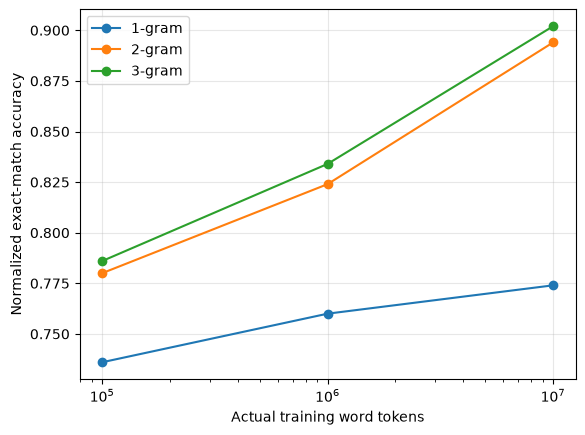

In [2]:
if not results.empty:
    display(results.pivot(index="actual_tokens", columns="order", values="exact_match_accuracy"))
    for order, group in results.groupby("order"):
        group = group.sort_values("actual_tokens")
        plt.plot(group.actual_tokens, group.exact_match_accuracy, marker="o", label=f"{order}-gram")
    plt.xscale("log")
    plt.xlabel("Actual training word tokens")
    plt.ylabel("Normalized exact-match accuracy")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()

In [3]:
if not results.empty:
    display(
        results[
            [
                "order",
                "actual_tokens",
                "wer",
                "cer",
                "mrr",
                "oracle_accuracy",
                "oov_hypotheses",
                "milliseconds_per_record",
                "binary_bytes",
                "training_seconds",
            ]
        ]
    )

,order,actual_tokens,wer,cer,mrr,oracle_accuracy,oov_hypotheses,milliseconds_per_record,binary_bytes,training_seconds
0,1,99987,0.046916,0.017666,0.851221,1.0,0.353315,0.060307,1169405,0.551915
1,2,99987,0.039748,0.014997,0.874902,1.0,0.353315,0.043186,2586905,0.382405
2,3,99987,0.039096,0.014711,0.878136,1.0,0.353315,0.037830,4714889,0.454474
3,1,999999,0.038445,0.016205,0.867219,1.0,0.176630,0.063368,5237199,0.816193
4,2,999999,0.028019,0.012170,0.903517,1.0,0.176630,0.039981,15683559,1.221509
5,3,999999,0.026064,0.011693,0.909683,1.0,0.176630,0.039446,33833975,2.119418
6,1,9999984,0.033449,0.015855,0.878317,1.0,0.108681,0.064903,20898257,3.075329
7,2,9999984,0.014770,0.007149,0.945667,1.0,0.108681,0.041641,90491645,8.303031
8,3,9999984,0.013467,0.006927,0.949833,1.0,0.108681,0.065732,235067377,16.638770


Discuss trends using actual results, including model size, OOV coverage, fixed baselines, and limitations. Do not interpret tiny test fixtures as assignment results.